# VOREKO IA — Actividad 5: Preparación de datos, entrenamiento y registro en MLflow

**Master de Inteligencia Artificial**  
José Ignacio Castillo Camacho

## 1. Entorno

In [1]:
import sys, os, subprocess, importlib, json, platform, warnings
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    %pip install -q "mlflow>=3.0" "xgboost>=2.0" openpyxl
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", category=FutureWarning)
from importlib.metadata import version
for p in ["pandas", "numpy", "scikit-learn", "xgboost", "scipy", "mlflow", "matplotlib", "openpyxl"]:
    print(f"{p:<14} {version(p)}")
print("Python", platform.python_version(), "| Entorno:", "Google Colab" if EN_COLAB else "local", "| CPU:", os.cpu_count())

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 395.8 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 38.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 102.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 59.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 23.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 14.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 2. Repositorio y rutas

In [2]:
from pathlib import Path
URL_REPO = "https://github.com/Ignacio-Castillo-C/voreko-ia-incidencias.git"
if EN_COLAB and not Path("fuentes/datos_prep.py").exists():
    if not Path("repo").exists():
        subprocess.run(["git", "clone", "-q", URL_REPO, "repo"], check=True)
    os.chdir("repo/Actividad5" if Path("repo/Actividad5").exists() else "repo")
RAIZ = Path.cwd().parent if Path.cwd().name == "fuentes" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "fuentes"))
import datos_prep as dp, visualizaciones as vis, train
for m in (dp, vis, train):
    importlib.reload(m)
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: /content/repo/Actividad5


## 3. Datos originales (versión 0)

In [3]:
ruta = dp.obtener_datos()
crudo = dp.leer_original(ruta)
huella = dp.sha256_dataframe(crudo)
print("Dimensiones con encabezados:", crudo.shape)
print("SHA-256 del contenido:", huella)
assert huella == "7e736374a647e1f64f930dab167dcf93bf8018c9d17b8a5891e5ce257b4671cd", "El archivo no coincide con la versión 0"
display(crudo.iloc[:4, :14])

Dimensiones con encabezados: (374, 109)
SHA-256 del contenido: 7e736374a647e1f64f930dab167dcf93bf8018c9d17b8a5891e5ce257b4671cd


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,PROJECT DATES (PERSIAN CALENDAR),NaN,NaN,NaN,PROJECT PHYSICAL AND FINANCIAL VARIABLES,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ECONOMIC VARIABLES AND INDICES IN TIME LAG 1,NaN
1,START YEAR,START QUARTER,COMPLETION YEAR,COMPLETION QUARTER,V-1,V-2,V-3,V-4,V-5,V-6,V-7,V-8,V-11,V-12
2,81,1,85,1,1,3150,920,598.5,190,1010.84,16,1200,6713,56.2
3,84,1,89,4,1,7600,1140,3040,400,963.81,23,2900,3152,106


## 4. Limpieza y estandarización

In [4]:
limpio, reporte = dp.limpiar(crudo)
import pandas as pd, numpy as np
pd.set_option("display.max_colwidth", 120)
for paso, info in reporte.items():
    print(f"── {paso}"); print(json.dumps(info, ensure_ascii=False, default=str, indent=1)[:900])

── 1_encabezados
{
 "filas_encabezado": 2,
 "columnas": 109,
 "codigos_repetidos_en_original": 76,
 "nombres_unicos_tras_aplanar": true
}
── 2_tipos
{
 "tipos_antes": {
  "object": 109
 },
 "tipos_despues": {
  "float64": 94,
  "int64": 15
 },
 "valores_no_convertibles": 0
}
── 3_nulos
{
 "nulos_totales": 0,
 "filas_sin_objetivo_eliminadas": 0,
 "celdas_imputadas_mediana": 0
}
── 4_duplicados
{
 "filas_iniciales": 372,
 "duplicados_exactos": 0,
 "duplicados_por_clave_proyecto": 0,
 "registros_en_grupos_casi_duplicados": 0,
 "columnas_duplicadas_eliminadas": [],
 "columnas_constantes_eliminadas": [],
 "filas_finales": 372
}
── 5_reglas_negocio
{
 "violaciones_por_regla": {
  "trimestres_en_1_4": 0,
  "localidad_en_1_20": 0,
  "areas_y_costos_positivos": 0,
  "area_construida_mayor_o_igual_terreno": 0,
  "costo_total_igual_m2_por_area": 0,
  "fin_igual_inicio_mas_duracion": 0,
  "duracion_positiva": 0
 },
 "filas_eliminadas": 0
}
── 6_estandarizacion
{
 "columnas_monetarias_a_MIRR": 51,


In [5]:
base, _ = dp.convertir_tipos(dp.aplanar_encabezados(crudo)[0])
sucio = pd.concat([base, base.iloc[[0, 1]], base.iloc[[2]].assign(precio_venta_real_m2=1)], ignore_index=True)
_, rep_dup = dp.deduplicar(sucio)
print({k: rep_dup[k] for k in ["filas_iniciales", "duplicados_exactos", "duplicados_por_clave_proyecto", "filas_finales"]})
assert rep_dup["filas_finales"] == len(base)

{'filas_iniciales': 375, 'duplicados_exactos': 2, 'duplicados_por_clave_proyecto': 1, 'filas_finales': 372}


In [6]:
manifiesto = dp.ejecutar()
print(json.dumps({k: manifiesto[k] for k in ["version_datos", "filas_original", "filas_limpio", "columnas_limpio", "predictoras", "huellas_sha256"]}, ensure_ascii=False, indent=1))
dic = pd.read_csv(dp.DICCIONARIO)
display(dic.groupby("rol").size().rename("columnas").to_frame())
display(dic.head(12))

{
 "version_datos": "1.0.0",
 "filas_original": 372,
 "filas_limpio": 372,
 "columnas_limpio": 117,
 "predictoras": 105,
 "huellas_sha256": {
  "archivo_original_xlsx": "56ccbc261b0f1ceb50e10e3f0cd02794f8cdd16a3ffb9788eeb505e706642655",
  "contenido_original_hoja_Data": "7e736374a647e1f64f930dab167dcf93bf8018c9d17b8a5891e5ce257b4671cd",
  "csv_limpio": "47e7de7fe5d195f1d1852bce258d43333044206db340d88128b069ed3fb5424b"
 }
}


,columnas
rol,
auxiliar (no predictora),6
excluida: Derivada de la fecha de término (fuga de información),1
excluida: Fecha de término: posterior al momento de estimar (fuga de información),2
excluida: Redundante: costo_prelim_m2 × area_construida_m2 (identidad verificada),1
excluida: Salida del proyecto: sólo se conoce al vender (fuga de información),1
objetivo,1
predictora,105


,columna,codigo_original,rezago,descripcion,unidad_original,unidad_limpia,tipo,rol
0,id_proyecto,derivada,NaN,Identificador asignado en la limpieza,NaN,NaN,object,auxiliar (no predictora)
1,anio_inicio,derivada,NaN,"Año de inicio (calendario persa, 4 dígitos)",NaN,NaN,int64,predictora
2,trimestre_inicio,derivada,NaN,Trimestre de inicio (persa; 1 = primavera),NaN,NaN,int64,predictora
3,anio_fin,derivada,NaN,"Año de término (calendario persa, 4 dígitos)",NaN,NaN,int64,excluida: Fecha de término: posterior al momento de estimar (fuga de información)
4,trimestre_fin,derivada,NaN,Trimestre de término (persa),NaN,NaN,int64,excluida: Fecha de término: posterior al momento de estimar (fuga de información)
5,localidad,V-1,NaN,Localidad del proyecto (código postal agrupado 1–20),NaN,categórica,int64,predictora
6,area_construida_m2,V-2,NaN,Área total construida del edificio,m2,m2,float64,predictora
7,area_terreno_m2,V-3,NaN,Área del terreno,m2,m2,float64,predictora
8,costo_prelim_total,V-4,NaN,Costo preliminar total estimado con precios al inicio,10M IRR,MIRR,float64,excluida: Redundante: costo_prelim_m2 × area_construida_m2 (identidad verificada)
9,costo_prelim_m2,V-5,NaN,Costo preliminar estimado por m2 con precios al inicio,10k IRR,MIRR/m2,float64,predictora


## 5. Versionado

In [7]:
r = subprocess.run(["git", "log", "--oneline", "-n", "10"], capture_output=True, text=True)
print(r.stdout or "Sin historial de git")

7186446 Update entrena.ipynb
c39e9e7 entrena.ipynb
52838fc Create .gitignore
eaa8b77 Add files via upload



## 6. Visualizaciones

eda_01_distribucion_objetivo.png {"asimetria_original": 1.26, "asimetria_log": -0.41, "mediana": 1.9, "max": 10.0}


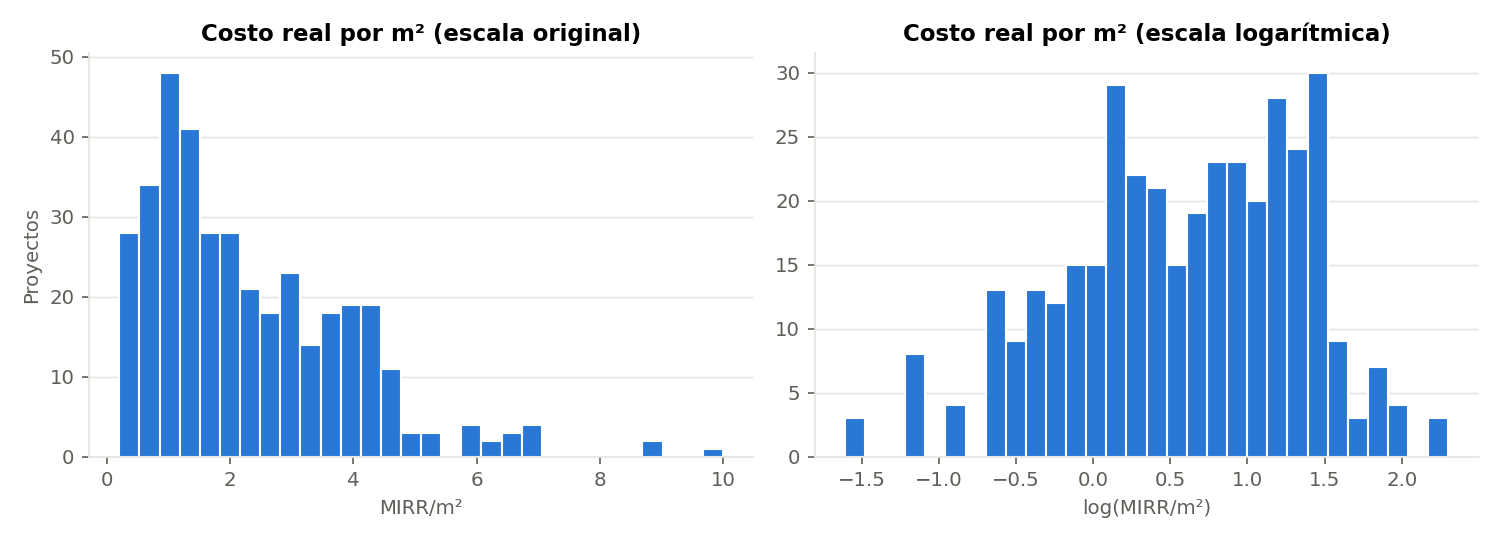

eda_02_tendencia_temporal.png {"costo_real_mediano_primer_anio": 0.3, "costo_real_mediano_ultimo_anio": 6.25, "razon_max_anio": 1373, "razon_max": 2.0, "razon_min_anio": 1377, "razon_min": 1.18, "proyectos_por_anio_min": 6, "proyectos_por_anio_max": 41}


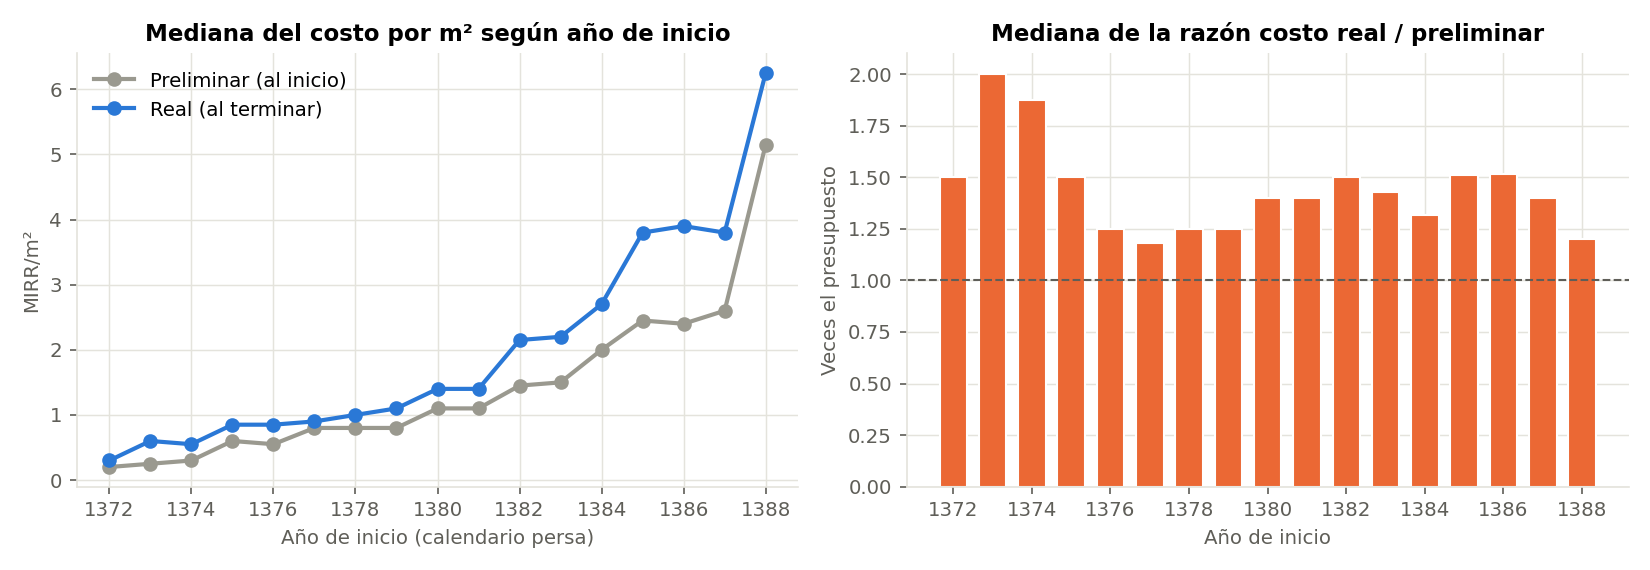

eda_03_preliminar_vs_real.png {"correlacion_log": 0.959, "razon_mediana": 1.41, "pct_sobre_presupuesto": 98.4, "anomalias": 12, "anios_anomalias": [1373, 1374, 1375, 1376], "prelim_max_en_anomalias": 0.6, "valores_distintos_prelim_bajo_1": 9}


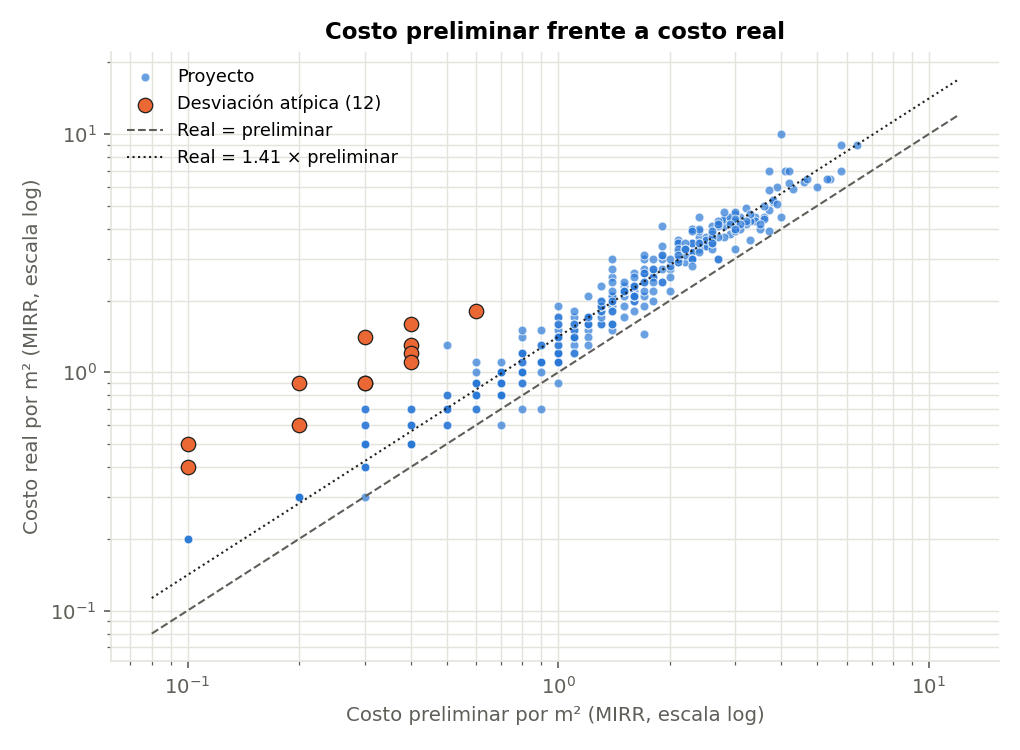

eda_04_costo_por_localidad.png {"localidades": 20, "min_proyectos_localidad": 4, "max_proyectos_localidad": 33}


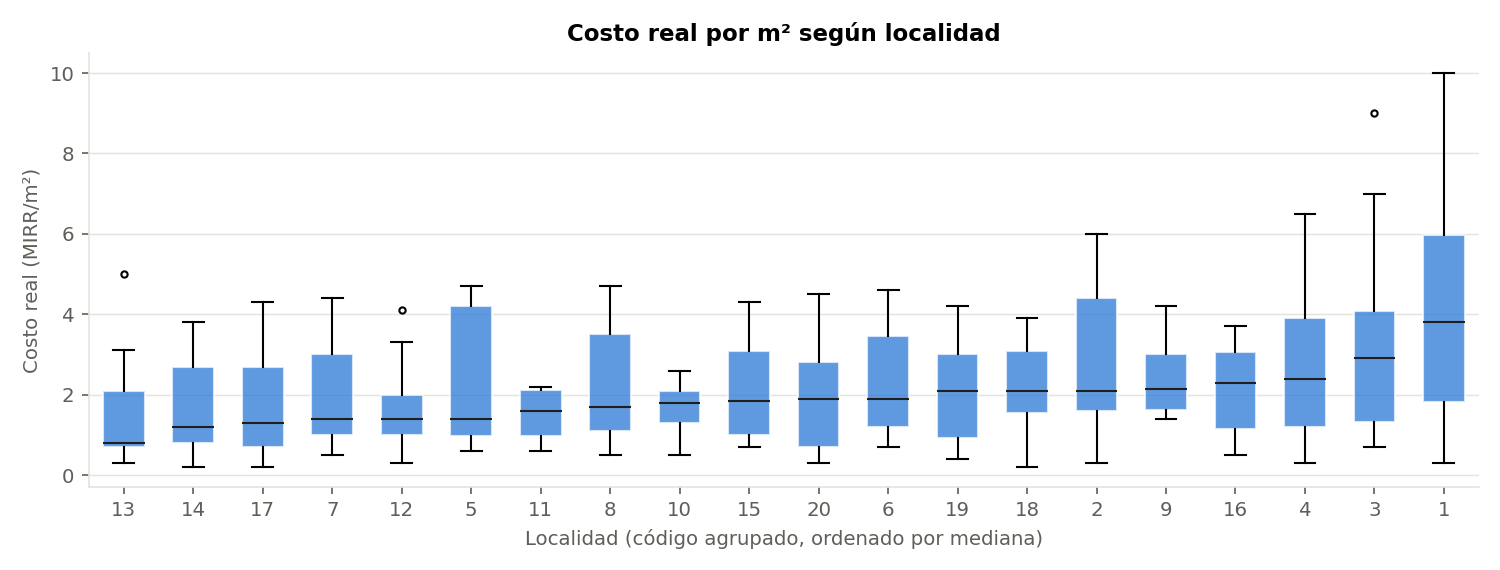

eda_05_correlacion_indicadores.png {"pares_predictoras": 5460, "pares_r_mayor_0_99": 183, "pares_r_mayor_0_9": 1302, "corr_mediana_r1_vs_r5_mismo_indicador": 0.957}


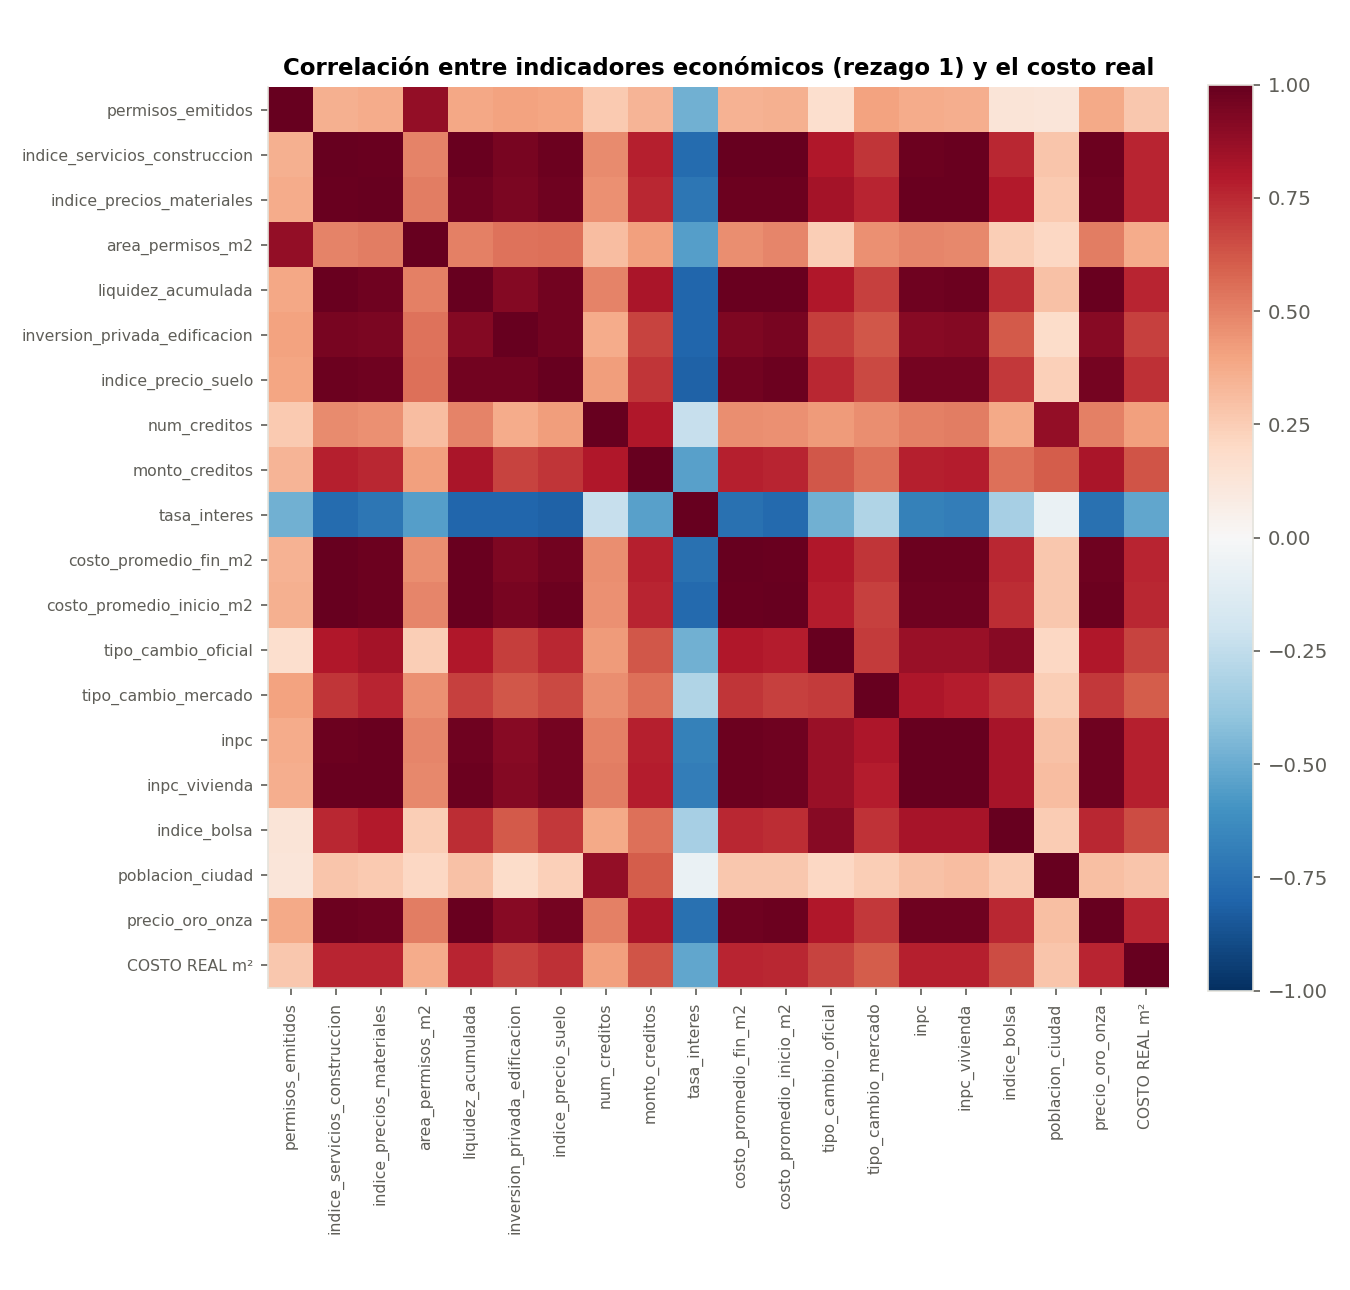

In [8]:
from IPython.display import Image, display
hallazgos = vis.generar_todas(limpio)
for nombre, datos in hallazgos.items():
    print(nombre, json.dumps(datos, ensure_ascii=False, default=str))
    display(Image(filename=str(vis.DIR_FIG / nombre), width=820))

## 7. Configuración de MLflow

In [9]:
import mlflow
uri = train.configurar_mlflow(None)
exp = mlflow.get_experiment_by_name(train.EXPERIMENTO)
print("Tracking URI:", uri); print("Experimento:", exp.name, "| id:", exp.experiment_id, "| artefactos:", exp.artifact_location)

2026/10/17 16:10:25 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/17 16:10:25 INFO mlflow.store.db.utils: Updating database tables


Tracking URI: sqlite:////content/repo/Actividad5/mlflow.db
Experimento: VOREKO-A5-costo-real-m2 | id: 1 | artefactos: file:///content/repo/Actividad5/mlruns


## 8. Modelos e hiperparámetros

In [10]:
for nombre, (est, grid) in train.definir_modelos().items():
    n = int(np.prod([len(v) for v in grid.values()]))
    print(f"{nombre:<13} {n:>3} combinaciones × 5 folds = {n*5:>3} ajustes | {grid}")

Ridge          12 combinaciones × 5 folds =  60 ajustes | {'regressor__rezagos__rezagos': ['todos', 'r1'], 'regressor__modelo__alpha': [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]}
RandomForest   24 combinaciones × 5 folds = 120 ajustes | {'regressor__rezagos__rezagos': ['todos', 'r1'], 'regressor__modelo__max_depth': [None, 10], 'regressor__modelo__min_samples_leaf': [1, 3, 5], 'regressor__modelo__max_features': [0.33, 1.0]}
XGBoost        32 combinaciones × 5 folds = 160 ajustes | {'regressor__rezagos__rezagos': ['todos', 'r1'], 'regressor__modelo__learning_rate': [0.03, 0.1], 'regressor__modelo__max_depth': [2, 4], 'regressor__modelo__colsample_bytree': [0.5, 0.8], 'regressor__modelo__min_child_weight': [1, 5]}


## 9. Entrenamiento y registro en MLflow

In [11]:
import time
inicio = time.time()
res = train.ejecutar_experimento()
print(f"Tiempo: {time.time()-inicio:.0f} s | runs en el experimento: {res['runs_registrados']} | commit: {res['git_commit']}")
print(json.dumps(res["seleccion"], ensure_ascii=False, indent=1, default=str))

Tiempo: 3093 s | runs en el experimento: 75 | commit: 7186446
{
 "modelo": "XGBoost",
 "criterio": "menor RMSE medio en validación cruzada anidada",
 "friedman_p": 0.0742735782143343,
 "registro": {
  "nombre": "voreko_costo_real_m2",
  "version": 1,
  "alias": "candidato"
 }
}


Successfully registered model 'voreko_costo_real_m2'.
Created version '1' of model 'voreko_costo_real_m2'.


## 10. Resultados

In [12]:
filas = []
for m, r in res["modelos"].items():
    filas.append({"modelo": m, "CV RMSE": r["cv_rmse"], "CV MAE": r["cv_mae"], "CV R²": r["cv_r2"],
                  "Prueba MAE": r["test_mae"], "Prueba RMSE": r["test_rmse"], "Prueba R²": r["test_r2"], "Prueba MAPE": r["test_mape"]})
tabla = pd.DataFrame(filas).set_index("modelo").sort_values("CV RMSE")
display(tabla.round(4))
display(pd.DataFrame({m: r.get("mejores_params", {}) for m, r in res["modelos"].items() if "mejores_params" in r}))

,CV RMSE,CV MAE,CV R²,Prueba MAE,Prueba RMSE,Prueba R²,Prueba MAPE
modelo,,,,,,,
XGBoost,0.2937,0.1822,0.9640,0.1879,0.4290,0.9408,0.0779
RandomForest,0.3694,0.2136,0.9449,0.2397,0.4770,0.9268,0.1030
ReglaPresupuestal,0.4177,0.2605,0.9275,0.2942,0.4398,0.9378,0.1407
Ridge,0.4330,0.2725,0.9115,0.3933,1.4418,0.3314,0.1491
Mediana,1.6303,1.2477,-0.0701,1.3053,1.8264,-0.0729,0.8608


,Ridge,RandomForest,XGBoost
alpha,100.0,NaN,NaN
rezagos,todos,r1,r1
max_depth,NaN,10,2
max_features,NaN,1.0,NaN
min_samples_leaf,NaN,3,NaN
colsample_bytree,NaN,NaN,0.8
learning_rate,NaN,NaN,0.1
min_child_weight,NaN,NaN,5


,rmse_mean,rmse_std,mae_mean,mae_std,r2_mean,r2_std,mape_mean,mape_std
modelo,,,,,,,,
XGBoost,0.3328,0.1427,0.1887,0.0413,0.9529,0.0320,0.0956,0.0101
RandomForest,0.3561,0.1285,0.2124,0.0450,0.9470,0.0276,0.1107,0.0127
ReglaPresupuestal,0.4156,0.1395,0.2616,0.0469,0.9283,0.0367,0.1335,0.0113
Ridge,0.5731,0.3914,0.2824,0.0490,0.7847,0.3352,0.1599,0.0244


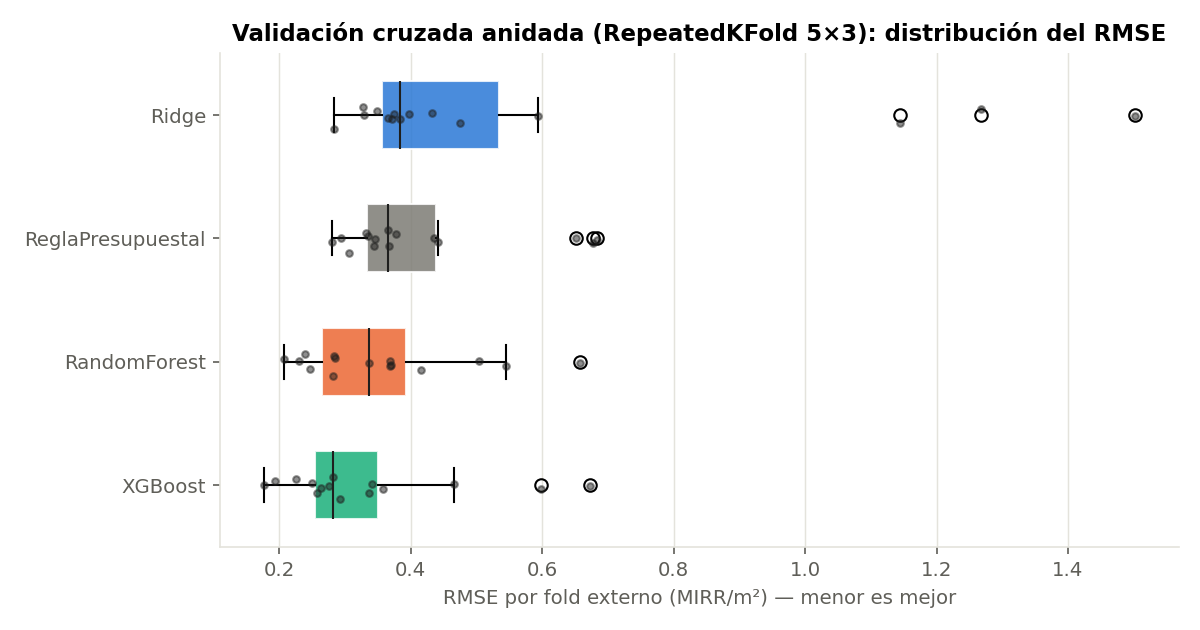

In [13]:
anidada = pd.read_csv(RAIZ / "resultados" / "cv_anidada_resumen.csv", index_col=0)
display(anidada.round(4))
display(Image(filename=str(RAIZ / "resultados" / "figuras" / "cv_anidada_rmse.png"), width=760))

## 11. Comparación estadística

In [14]:
pruebas = pd.read_csv(RAIZ / "resultados" / "pruebas_estadisticas.csv")
display(pruebas.round(4))
print(f"Friedman (3 modelos ajustados): χ² = {res['friedman']['estadistico']:.3f}, p = {res['friedman']['p']:.4f}")

,comparacion,dif_media_rmse,t_corregida,p_t_corregida,p_wilcoxon,gana_a_en_folds,folds,p_t_holm,p_wilcoxon_holm,significativa_0_05
0,Ridge_vs_RandomForest,0.2169,0.9030,0.3818,0.0946,4,15,1.0000,0.2838,False
1,Ridge_vs_XGBoost,0.2403,0.9741,0.3465,0.0413,4,15,1.0000,0.1650,False
2,Ridge_vs_ReglaPresupuestal,0.1575,0.6380,0.5338,0.5614,8,15,1.0000,0.5614,False
3,RandomForest_vs_XGBoost,0.0234,0.8089,0.4321,0.1354,6,15,1.0000,0.2838,False
4,RandomForest_vs_ReglaPresupuestal,-0.0595,-1.5643,0.1401,0.0067,13,15,0.7003,0.0336,False
5,XGBoost_vs_ReglaPresupuestal,-0.0828,-2.7598,0.0153,0.0001,15,15,0.0921,0.0004,False


Friedman (3 modelos ajustados): χ² = 5.200, p = 0.0743


## 12. Diagnóstico del modelo seleccionado

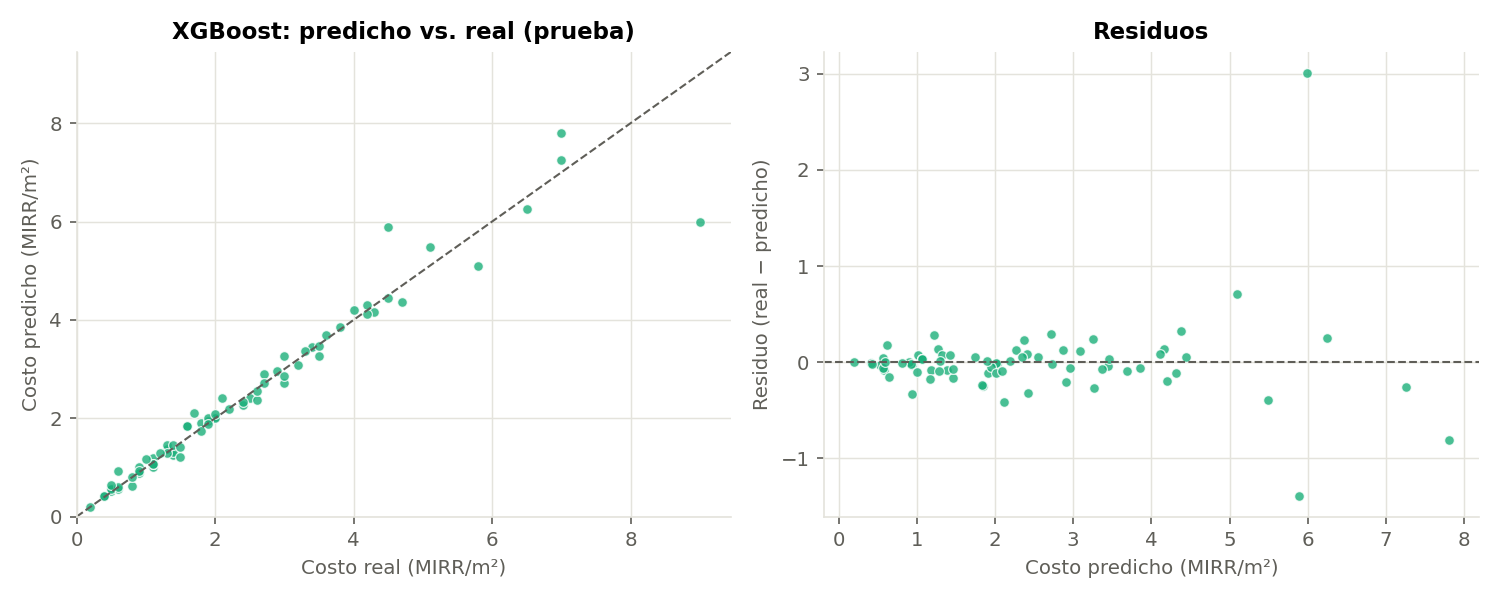

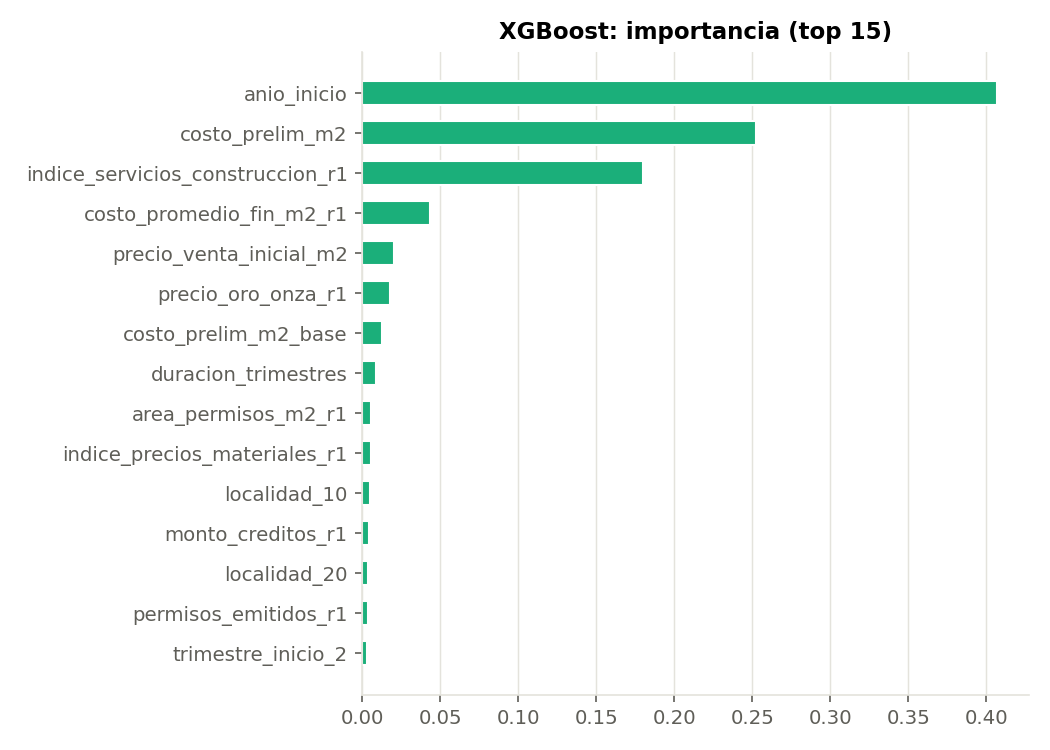

Variables más importantes: {'anio_inicio': 0.4066999852657318, 'costo_prelim_m2': 0.2524000108242035, 'indice_servicios_construccion_r1': 0.17990000545978546, 'costo_promedio_fin_m2_r1': 0.04349999874830246, 'precio_venta_inicial_m2': 0.0203000009059906}


In [15]:
ganador = res["seleccion"]["modelo"]
for f in [f"pred_vs_real_{ganador}.png", f"importancia_{ganador}.png"]:
    display(Image(filename=str(RAIZ / "resultados" / "figuras" / f), width=760))
print("Variables más importantes:", res["modelos"][ganador]["top_variables"])

## 13. Runs y Model Registry

In [16]:
runs = mlflow.search_runs([exp.experiment_id])
cols = ["tags.mlflow.runName", "tags.etapa", "tags.modelo", "metrics.cv_rmse", "metrics.test_rmse", "metrics.test_r2", "tags.git_commit", "tags.version_datos"]
display(runs[[c for c in cols if c in runs.columns]].query("`tags.etapa` != 'candidato'").head(12))
print("Total de runs (incluye candidatos del grid):", len(runs))
modelo_registrado = mlflow.sklearn.load_model(f"models:/{train.NOMBRE_REGISTRO}@candidato")
df_l = pd.read_csv(dp.CSV_LIMPIO); X, y = dp.seleccionar_variables(df_l)
ganador = res["seleccion"]["modelo"]
pred_reg = modelo_registrado.predict(X.head(5))
pred_run = mlflow.sklearn.load_model(res["modelos"][ganador]["model_uri"]).predict(X.head(5))
print("Predicción del modelo registrado (MIRR/m²):", np.round(pred_reg, 3))
print("¿Idéntica a la del run?", bool(np.allclose(pred_reg, pred_run, rtol=0, atol=1e-12)))

,tags.mlflow.runName,tags.etapa,tags.modelo,metrics.cv_rmse,metrics.test_rmse,metrics.test_r2,tags.git_commit,tags.version_datos
0,04_cv_anidada_comparacion,comparacion,None,NaN,NaN,NaN,7186446,1.0.0
1,03_referencia_Mediana,referencia,Mediana,1.630321,1.826436,-0.072871,7186446,1.0.0
2,03_referencia_ReglaPresupuestal,referencia,ReglaPresupuestal,0.417705,0.439848,0.937778,7186446,1.0.0
35,02_gridsearch_XGBoost,ajuste,XGBoost,0.293654,0.428958,0.940821,7186446,1.0.0
60,02_gridsearch_RandomForest,ajuste,RandomForest,0.369387,0.476957,0.926836,7186446,1.0.0
73,02_gridsearch_Ridge,ajuste,Ridge,0.432985,1.441808,0.331420,7186446,1.0.0
74,01_datos_v1.0.0,datos,None,NaN,NaN,NaN,7186446,1.0.0


Total de runs (incluye candidatos del grid): 75
Predicción del modelo registrado (MIRR/m²): [3.913 9.306 2.115 0.299 7.725]
¿Idéntica a la del run? True


## 14. Panel de MLflow

In [17]:
import time, urllib.request
srv_mlflow = subprocess.Popen([sys.executable, "-m", "mlflow", "server", "--backend-store-uri", f"sqlite:///{RAIZ / 'mlflow.db'}",
                               "--host", "127.0.0.1", "--port", "5000", "--workers", "1",
                               "--allowed-hosts", "*", "--cors-allowed-origins", "*"],
                              cwd=RAIZ, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
for _ in range(60):
    try:
        urllib.request.urlopen("http://127.0.0.1:5000/health", timeout=2); break
    except Exception:
        time.sleep(1)
print("Servidor de MLflow activo en el puerto 5000")
if EN_COLAB:
    from google.colab import output
    output.serve_kernel_port_as_window(5000, anchor_text="Abrir el panel de MLflow")

Servidor de MLflow activo en el puerto 5000
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

## 15. Alerta de desviación de costo

In [18]:
from sklearn.metrics import roc_auc_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
modelo = mlflow.sklearn.load_model(res["modelos"][ganador]["model_uri"])
estratos = pd.qcut(y, 5, labels=False)
_, X_te, _, y_te = train_test_split(X, y, test_size=0.2, random_state=train.SEMILLA, stratify=estratos)
razon_real = y_te / X_te["costo_prelim_m2"]; razon_est = modelo.predict(X_te) / X_te["costo_prelim_m2"]
real_alta, alerta = razon_real > 1.5, razon_est > 1.5
print(f"Obras de prueba: {len(y_te)} | con desviación real > 50 %: {int(real_alta.sum())}")
print(f"Alertas emitidas: {int(alerta.sum())} | recall {recall_score(real_alta, alerta, zero_division=0):.3f} | "
      f"precision {precision_score(real_alta, alerta, zero_division=0):.3f} | ROC-AUC de la razón estimada {roc_auc_score(real_alta, razon_est):.3f}")

Obras de prueba: 75 | con desviación real > 50 %: 26
Alertas emitidas: 23 | recall 0.692 | precision 0.783 | ROC-AUC de la razón estimada 0.859


## 16. Exportación de resultados

In [19]:
import shutil, tempfile
tmp = Path(tempfile.mkdtemp()) / "resultados_colab"
for carpeta in ["resultados", "datos/datos_limp", "mlruns"]:
    if (RAIZ / carpeta).exists():
        shutil.copytree(RAIZ / carpeta, tmp / carpeta)
shutil.copy2(RAIZ / "mlflow.db", tmp / "mlflow.db")
zip_path = shutil.make_archive(str(RAIZ / "resultados_colab"), "zip", tmp)
print("Archivo:", zip_path, f"({Path(zip_path).stat().st_size / 1e6:.1f} MB)")
if EN_COLAB:
    from google.colab import files
    files.download(zip_path)

Archivo: /content/repo/Actividad5/resultados_colab.zip (2.4 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>